# Tugas Praktikum 6: Clustering (Advance)

Nama  : Levina Zahrathul Huda \
NRP   : 5054251033

# Unduh dan Import Dataset


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.cluster import SpectralClustering
from sklearn.metrics import silhouette_score
from sklearn.metrics import rand_score
from sklearn.metrics import normalized_mutual_info_score
from sklearn.metrics import adjusted_rand_score
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.model_selection import train_test_split

In [4]:
url = "https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv"
df = pd.read_csv(url)
display(df.head())
print("Ukuran dataset:", df.shape)
df.info()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


Ukuran dataset: (344, 8)
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 21.6 KB


# Eksplorasi dan Pembersihan Data

In [10]:
# Missing values
missing = df.isna().sum()
print(missing [missing > 0])
print("Jumlah missing values:", df.isna().sum().sum())

bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64
Jumlah missing values: 19


In [14]:
# Menghapus baris yang nilainya kosong
features = [
    'bill_length_mm',
    'bill_depth_mm',
    'flipper_length_mm',
    'body_mass_g'
]

df_clean = df.dropna(subset=features + ['species']).copy()

In [16]:
# Statistik deskriptif
display(df_clean[features].describe())

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


In [21]:
# Jumlah baris sebelum dan sesudah pembersihan & jumlah data per spesies
print("Jumlah data sebelum pembersihan:", len(df))
print("Jumlah data sesudah pembersihan:", len(df_clean))

print("\nJumlah data per spesies:")
print(df_clean['species'].value_counts())

Jumlah data sebelum pembersihan: 344
Jumlah data sesudah pembersihan: 342

Jumlah data per spesies:
species
Adelie       151
Gentoo       123
Chinstrap     68
Name: count, dtype: int64


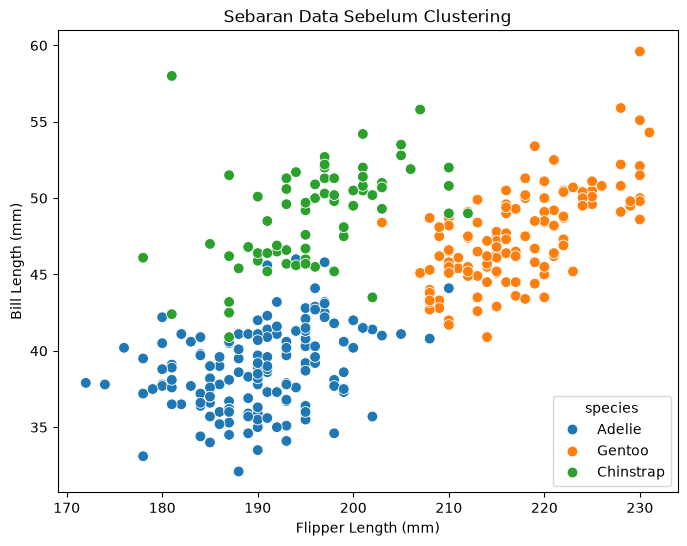

In [22]:
# Scatter plot
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df_clean,
    x='flipper_length_mm',
    y='bill_length_mm',
    hue='species',
    s=60
)

plt.title("Sebaran Data Sebelum Clustering")
plt.xlabel("Flipper Length (mm)")
plt.ylabel("Bill Length (mm)")
plt.show()

# Standardisasi Data

In [23]:
X = df_clean[features]
y = df_clean['species']

In [30]:
# Standardisasi X dengan z-score (StandardScaler)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=features)

display(X_scaled_df.head())
display(X_scaled_df.describe())

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,-0.884499,0.785449,-1.418347,-0.564142
1,-0.811126,0.126188,-1.062250,-0.501703
2,-0.664380,0.430462,-0.421277,-1.188532
3,-1.324737,1.089724,-0.563715,-0.938776
4,-0.847812,1.748985,-0.777373,-0.689020


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,3.420000e+02,3.420000e+02,3.420000e+02,3.420000e+02
mean,1.662088e-16,4.155221e-16,-8.310441e-16,8.310441e-17
std,1.001465e+00,1.001465e+00,1.001465e+00,1.001465e+00
min,-2.168526e+00,-2.054446e+00,-2.059320e+00,-1.875362e+00
25%,-8.615697e-01,-7.866355e-01,-7.773731e-01,-8.138982e-01
50%,9.686524e-02,7.547549e-02,-2.788381e-01,-1.895079e-01
75%,8.397670e-01,7.854492e-01,8.606705e-01,6.846384e-01
max,2.875868e+00,2.205397e+00,2.142618e+00,2.620248e+00


# Penerapan Algoritma

In [33]:
agg = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'      # Jenis linkage yang dipakai adalah ward
)

agg_labels = agg.fit_predict(X_scaled)

print("Jumlah anggota tiap cluster:")
print(pd.Series(agg_labels).value_counts().sort_index())

Jumlah anggota tiap cluster:
0    162
1    123
2     57
Name: count, dtype: int64


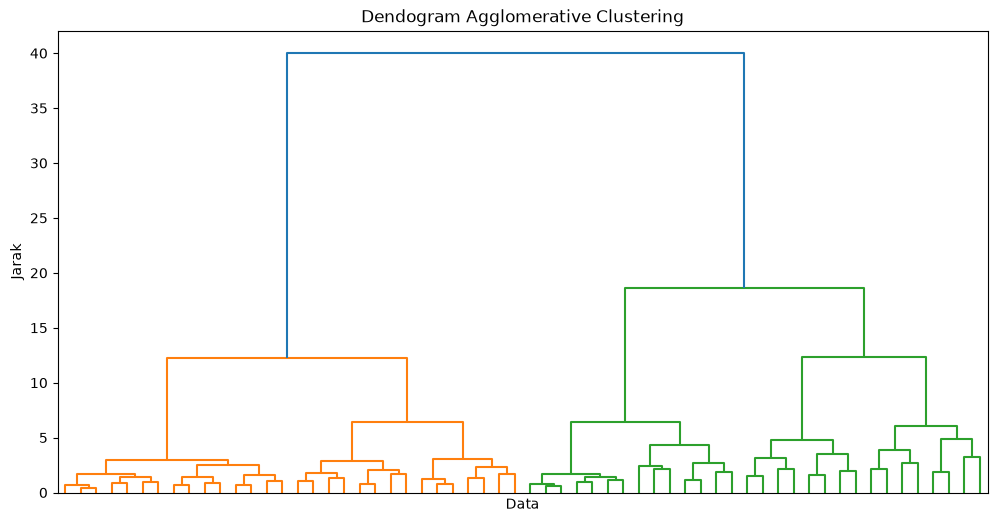

In [35]:
# Dendogram
linkage_matrix = linkage(X_scaled, method='ward')
plt.figure(figsize=(12, 6))
dendrogram(
    linkage_matrix,
    truncate_mode='level',
    p=5,
    show_leaf_counts=True,
    no_labels=True
)

plt.title("Dendogram Agglomerative Clustering")
plt.xlabel("Data")
plt.ylabel("Jarak")
plt.show()

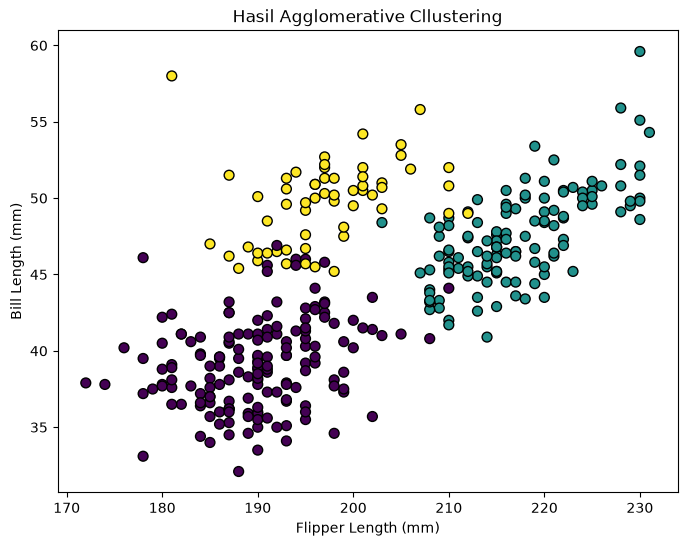

In [36]:
plt.figure(figsize=(8, 6))
plt.scatter(
    df_clean['flipper_length_mm'],
    df_clean['bill_length_mm'],
    c=agg_labels,
    cmap='viridis',
    edgecolor='k',
    s=50
)

plt.title('Hasil Agglomerative Cllustering')
plt.xlabel("Flipper Length (mm)")
plt.ylabel("Bill Length (mm)")
plt.show()

In [ ]:
dbscan = DBSCAN(
    eps=0.5,
    min_samples=5
)

dbscan_labels = dbscan.fit_predict(X_scaled)
jumlah_cluster = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
jumlah_noise = list(dbscan_labels).count(-1)
print("Jumlah cluster:", jumlah_cluster)
print("Jumlah noise:", jumlah_noise)
print("\nJumlah anggota tiap cluster:")
print(pd.Series(dbscan_labels).value_counts().sort_index())

Jumlah cluster: 4
Jumlah noise: 69

Jumlah anggota tiap cluster:
-1     69
 0    118
 1    113
 2     15
 3     27
Name: count, dtype: int64


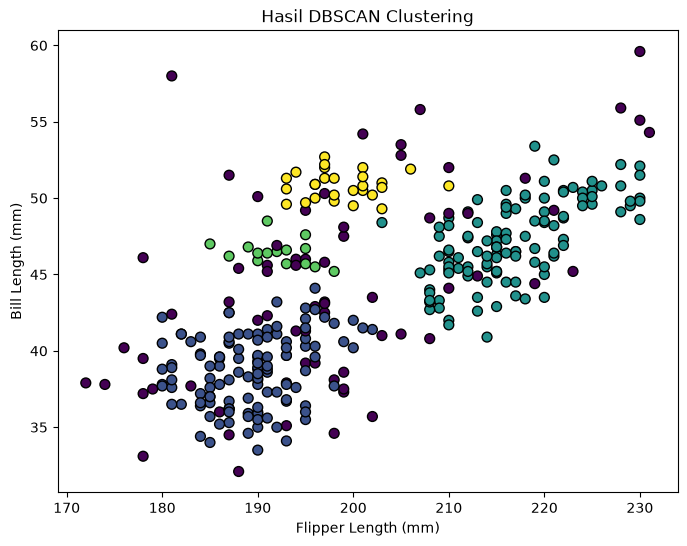

In [47]:
plt.figure(figsize=(8, 6))
plt.scatter(
    df_clean['flipper_length_mm'],
    df_clean['bill_length_mm'],
    c=dbscan_labels,
    cmap='viridis',
    edgecolor='k',
    s=50
)

plt.title("Hasil DBSCAN Clustering")
plt.xlabel("Flipper Length (mm)")
plt.ylabel("Bill Length (mm)")
plt.show()

In [40]:
eps_values = [0.5, 0.7, 0.9, 1.1, 1.3]
hasil_dbscan = []

for eps in eps_values:
    model = DBSCAN(
        eps=eps,
        min_samples=5
    )

    labels = model.fit_predict(X_scaled)
    jumlah_cluster - len(set(labels)) - (1 if -1 in labels else 0)
    jumlah_noise = list(labels).count(-1)
    hasil_dbscan.append({
        'eps': eps,
        'Jumlah Cluster': jumlah_cluster,
        'Jumlah Noise': jumlah_noise
    })

    tabel_dbscan = pd.DataFrame(hasil_dbscan)
    display(tabel_dbscan)

,eps,Jumlah Cluster,Jumlah Noise
0,0.5,4,69


,eps,Jumlah Cluster,Jumlah Noise
0,0.5,4,69
1,0.7,4,16


,eps,Jumlah Cluster,Jumlah Noise
0,0.5,4,69
1,0.7,4,16
2,0.9,4,2


,eps,Jumlah Cluster,Jumlah Noise
0,0.5,4,69
1,0.7,4,16
2,0.9,4,2
3,1.1,4,1


,eps,Jumlah Cluster,Jumlah Noise
0,0.5,4,69
1,0.7,4,16
2,0.9,4,2
3,1.1,4,1
4,1.3,4,1


Jumlah anggota tiap cluster:
0     67
1    123
2    152
Name: count, dtype: int64


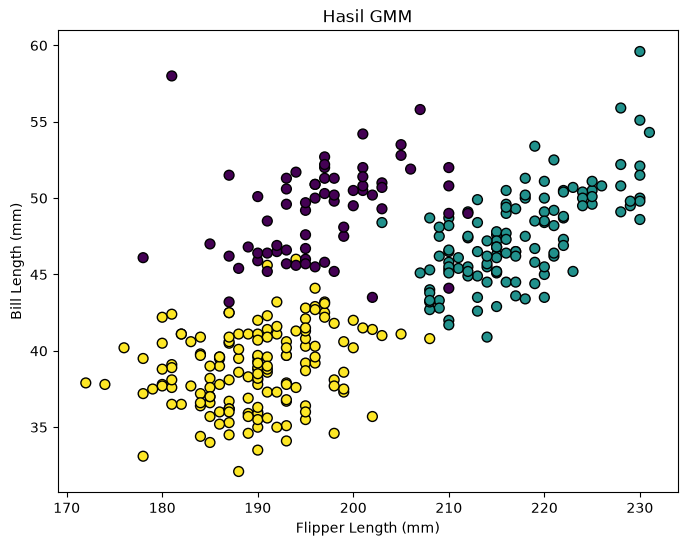

In [45]:
gmm = GaussianMixture(
    n_components=3,
    random_state=42
)

gmm.fit(X_scaled)
gmm_labels = gmm.predict(X_scaled)

print("Jumlah anggota tiap cluster:")
print(pd.Series(gmm_labels).value_counts().sort_index())

plt.figure(figsize=(8, 6))
plt.scatter(
    df_clean['flipper_length_mm'],
    df_clean['bill_length_mm'],
    c=gmm_labels,
    cmap='viridis',
    edgecolor='k',
    s=50
)

plt.title("Hasil GMM")
plt.xlabel("Flipper Length (mm)")
plt.ylabel("Bill Length (mm)")
plt.show()

c:\Users\Levina\miniconda3\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


Jumlah anggota tiap cluster:
0    162
1    123
2     57
Name: count, dtype: int64


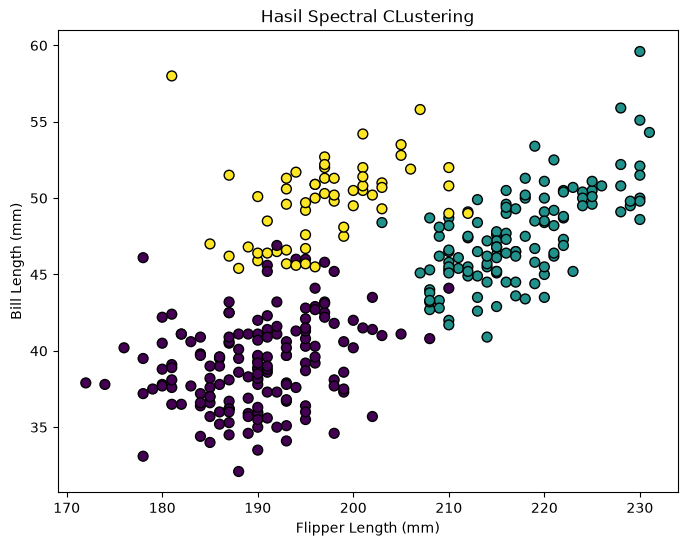

In [51]:
spectral = SpectralClustering(
    n_clusters=3,
    affinity='nearest_neighbors',
    n_neighbors=10,
    random_state=42
)

spectral_labels = spectral.fit_predict(X_scaled)

print("Jumlah anggota tiap cluster:")
print(pd.Series(spectral_labels).value_counts().sort_index())

plt.figure(figsize=(8, 6))
plt.scatter(
    df_clean['flipper_length_mm'],
    df_clean['bill_length_mm'],
    c=spectral_labels,
    cmap='viridis',
    edgecolor='k',
    s=50
)

plt.title("Hasil Spectral CLustering")
plt.xlabel("Flipper Length (mm)")
plt.ylabel("Bill Length (mm)")
plt.show()

# Evaluasi Hasil CLustering

In [52]:
hasil_clustering = {
    'Agglomerative': agg_labels,
    'DBSCAN': dbscan_labels,
    'GMM': gmm_labels,
    'Spectral': spectral_labels
}

hasil_silhouette = []

for nama, labels in hasil_clustering.items():
    if nama == 'DBSCAN':
        mask = labels != -1
        X_evaluasi = X_scaled[mask]
        labels_evaluasi = labels[mask]
        jumlah_drop = sum(labels == -1)
    else:
        X_evaluasi = X_scaled
        labels_evaluasi = labels
        jumlah_drop = 0

    jumlah_cluster = len(set(labels_evaluasi))
    if jumlah_cluster >= 2 and jumlah_cluster < len(labels_evaluasi):
        score = silhouette_score(
            X_evaluasi,
            labels_evaluasi
        )
    else:
        score = np.nan

    hasil_silhouette.append({
        'Algoritma': nama,
        'Silhoueete Score': score,
        'Data di-drop': jumlah_drop
    })

tabel_silhouette = pd.DataFrame(hasil_silhouette)
display(tabel_silhouette)

,Algoritma,Silhoueete Score,Data di-drop
0,Agglomerative,0.454095,0
1,DBSCAN,0.423504,69
2,GMM,0.454549,0
3,Spectral,0.454971,0


In [56]:
# Hitung Ran Index dan NMI
hasil_eksternal = []
for nama, labels in hasil_clustering.items():
    ri = rand_score(y, labels)
    nmi = normalized_mutual_info_score(y, labels)
    hasil_eksternal.append({
        'Algoritma': nama,
        'Rand Index': ri,
        'NMI': nmi
    })

tabel_eksternal = pd.DataFrame(hasil_eksternal)
display(tabel_eksternal)

,Algoritma,Rand Index,NMI
0,Agglomerative,0.960762,0.900710
1,DBSCAN,0.852532,0.663146
2,GMM,0.981650,0.934940
3,Spectral,0.960762,0.900710


In [57]:
def jalankan_clustering(nama, X):
    if nama == 'Agglomerative':
        model = AgglomerativeClustering(
            n_clusters=3,
            linkage='ward'
        )
    elif nama == 'DBSCAN':
        model = DBSCAN(
            eps=0.5,
            min_samples=5
        )
    elif nama == 'GMM':
        model = GaussianMixture(
            n_components=3,
            random_state=42
        )
    elif nama == 'Spectral':
        model = SpectralClustering(
            n_clusters=3,
            affinity='nearest_neighbors',
            n_neighbors=10,
            random_state=42
        )

    labels = model.fit_predict(X)
    return labels

In [59]:
hasil_stabilitas = []

random_state = 42
rng = np.random.RandomState(random_state)

for nama, labels_full in hasil_clustering.items():
    skor_stabilitas = []

    for percobaan in range(3):
        jumlah_sample = int(0.9 * len(X_scaled))
        index = rng.choice(
            len(X_scaled),
            size=jumlah_sample,
            replace=False
        )

    X_sample = X_scaled[index]
    labels_sample = jalankan_clustering(
        nama,
        X_sample
    )
    labels_full_sample = labels_full[index]
    skor = adjusted_rand_score(
        labels_full_sample,
        labels_sample
    )
    skor_stabilitas.append(skor)

    print(
        nama,
        "- Percobaan",
        percobaan + 1,
        ":",
        round(skor, 4)
    )

hasil_stabilitas.append({
    'Algoritma': nama,
    'Stabilitas Rata-rata': np.mean(skor_stabilitas),
    'Standar Deviasi': np.std(skor_stabilitas)
})
tabel_stabilitas = pd.DataFrame(hasil_stabilitas)
display(tabel_stabilitas)

Agglomerative - Percobaan 3 : 0.9314
DBSCAN - Percobaan 3 : 0.9245
GMM - Percobaan 3 : 0.9911
Spectral - Percobaan 3 : 0.8544


c:\Users\Levina\miniconda3\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


,Algoritma,Stabilitas Rata-rata,Standar Deviasi
0,Spectral,0.854375,0.0


In [60]:
# tabel perbandingan
tabel_perbandingan = tabel_silhouette.merge(
    tabel_eksternal,
    on='Algoritma'
)
tabel_perbandingan = tabel_perbandingan.merge(
    tabel_stabilitas,
    on='Algoritma'
)
display(tabel_perbandingan.round(4))

,Algoritma,Silhoueete Score,Data di-drop,Rand Index,NMI,Stabilitas Rata-rata,Standar Deviasi
0,Spectral,0.455,0,0.9608,0.9007,0.8544,0.0
